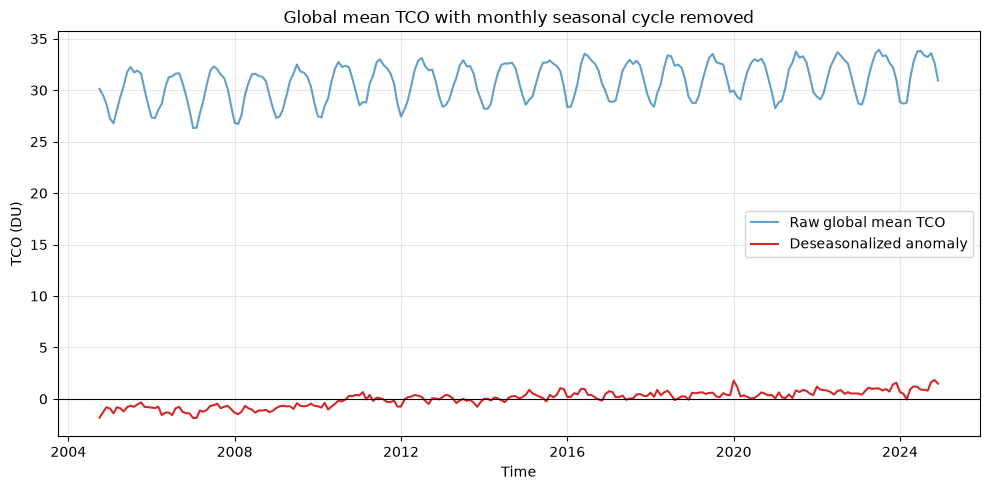

In [14]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

nc_file = "tco_omimls_v2_oct2004_to_dec2025_1by1.nc"
varname = "TropoO3"

ds = xr.open_dataset(nc_file)
tco = ds[varname]
# 缺失值转nan
tco = tco.where(tco != -999.0)  

lat = ds["Latitude"]
lon = ds["Longitude"]
time_str = ds["Time"].values  
# 替换成正确的时间坐标
time = pd.to_datetime(time_str, format="%b%Y")

ds = ds.assign_coords(Time=time)
tco = tco.assign_coords(Time=time)

# 面积加权全球平均
lat_weight = np.cos(np.radians(lat))
lat_weight = xr.DataArray(lat_weight, dims="Latitude")

tco_global = tco.weighted(lat_weight).mean(dim=["Latitude", "Longitude"])

month = tco_global["Time"].dt.month
tco_climatology = tco_global.groupby(month).mean()
tco_anomaly = tco_global.groupby(month) - tco_climatology

plt.figure(figsize=(10, 5))
plt.plot(tco_global["Time"], tco_global, label="Raw global mean TCO", color="tab:blue", alpha=0.7)
plt.plot(tco_anomaly["Time"], tco_anomaly, label="Deseasonalized anomaly", color="tab:red")
plt.axhline(y=0, c="k", lw=0.8)
plt.xlabel("Time")
plt.ylabel("TCO (DU)")
plt.title("Global mean TCO with monthly seasonal cycle removed")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("Global mean TCO with monthly seasonal cycle removed.png", dpi=300)
plt.show()

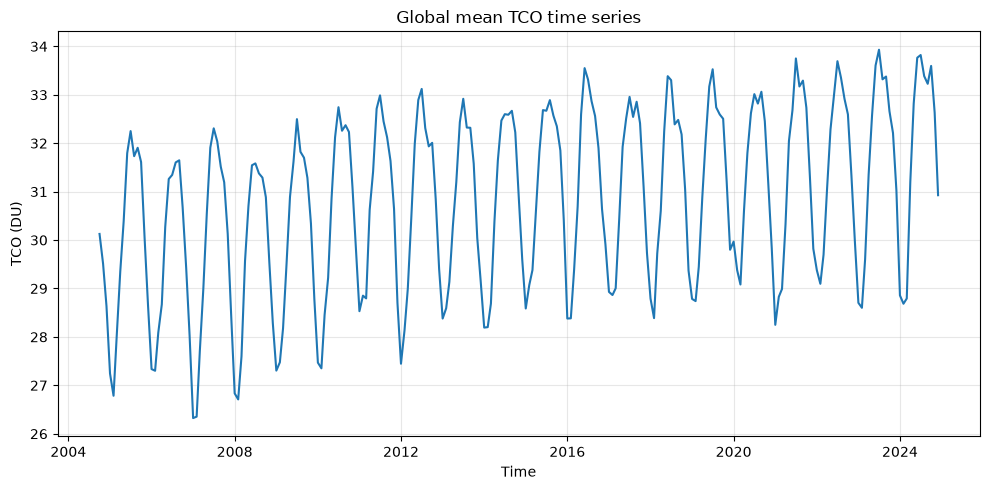

In [13]:
plt.figure(figsize=(10, 5))
plt.plot(tco_global["Time"], tco_global, color="tab:blue")
plt.xlabel("Time")
plt.ylabel("TCO (DU)")
plt.title("Global mean TCO time series")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("Global mean TCO time series.png", dpi=300)
plt.show()

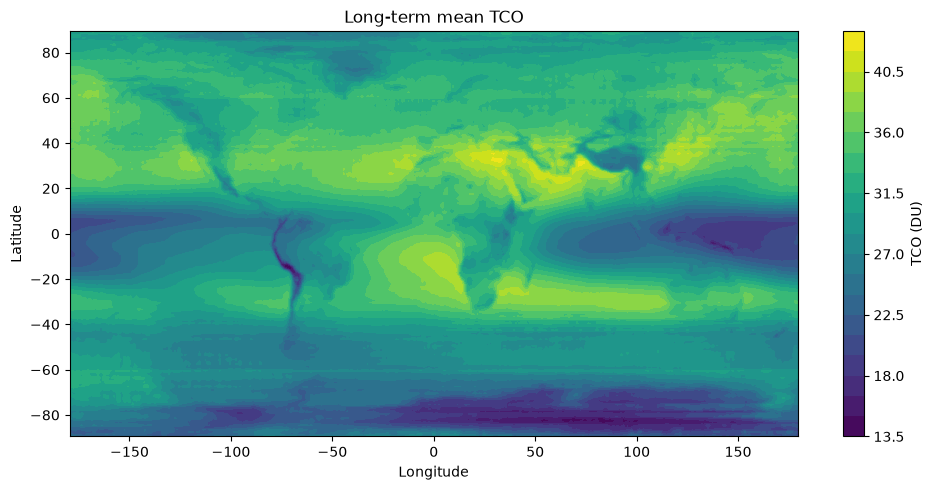

In [15]:
tco_mean = tco.mean(dim="Time")
plt.figure(figsize=(10, 5))
plt.contourf(lon, lat, tco_mean, levels=20, cmap="viridis")
plt.colorbar(label="TCO (DU)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Long-term mean TCO")
plt.tight_layout()
plt.savefig("Long-term mean TCO.png", dpi=300)
plt.show()

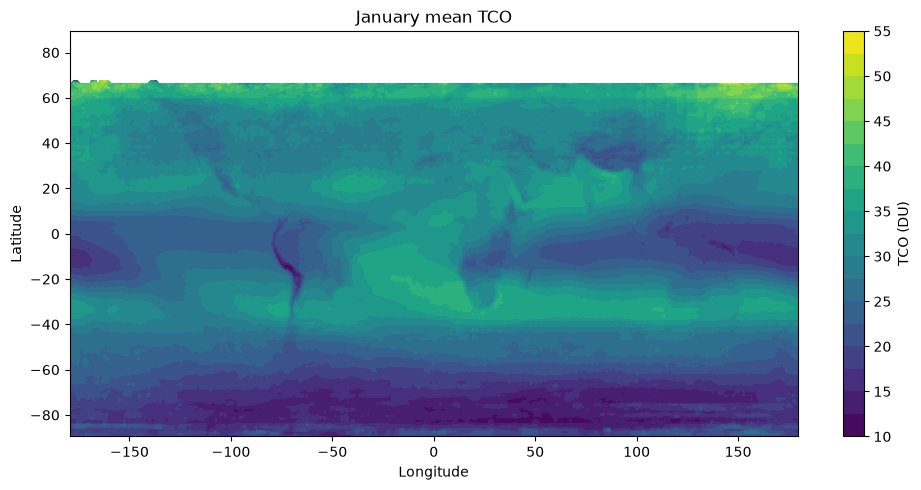

In [16]:
jan = tco.groupby("Time.month").mean(dim="Time").sel(month=1)
plt.figure(figsize=(10, 5))
plt.contourf(lon, lat, jan, levels=20, cmap="viridis")
plt.colorbar(label="TCO (DU)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("January mean TCO")
plt.tight_layout()
plt.savefig("January mean TCO.png", dpi=300)
plt.show()

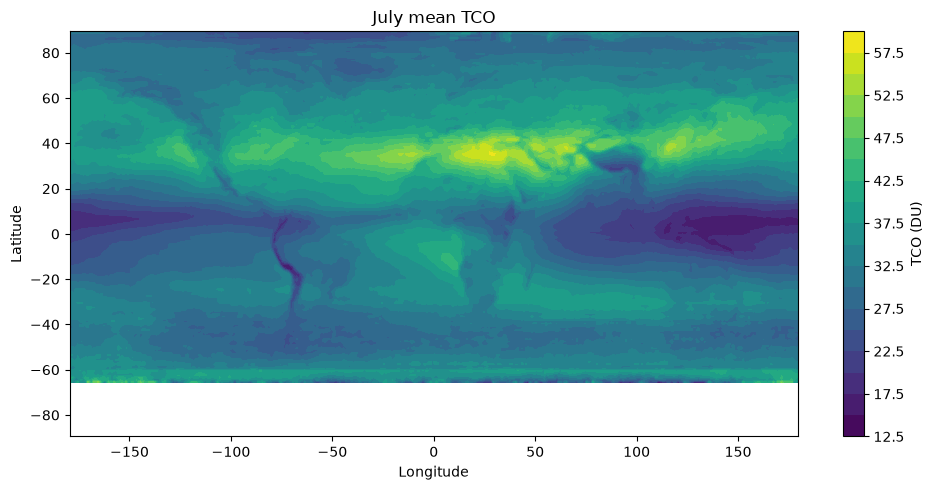

In [17]:
jul = tco.groupby("Time.month").mean(dim="Time").sel(month=7)
plt.figure(figsize=(10, 5))
plt.contourf(lon, lat, jul, levels=20, cmap="viridis")
plt.colorbar(label="TCO (DU)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("July mean TCO")
plt.tight_layout()
plt.savefig("July mean TCO.png", dpi=300)
plt.show()

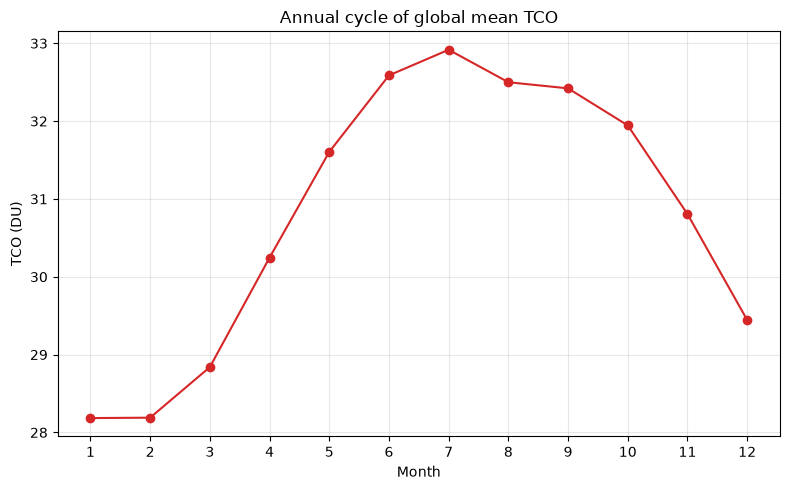

In [18]:
tco_clim_cycle = tco_global.groupby(tco_global["Time"].dt.month).mean()
plt.figure(figsize=(8, 5))
plt.plot(tco_clim_cycle.month, tco_clim_cycle, marker="o", color="tab:red")
plt.xticks(np.arange(1, 13))
plt.xlabel("Month")
plt.ylabel("TCO (DU)")
plt.title("Annual cycle of global mean TCO")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("Annual cycle of global mean TCO.png", dpi=300)
plt.show()